# MURA XR_WRIST - saved results viewer

This notebook is a **read-only presentation of committed project artifacts** for GitHub. It does not access raw MURA images, retrain a model, recompute metrics, select a threshold, or use official MURA `valid` for any new decision.

The historical Phase-1 official-valid reference has already been observed. All later Phase-2 material shown here is explicitly development/validation evidence, not an untouched final-test claim.

In [1]:
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SAFE_ARTIFACTS = [
    ROOT / 'reports' / 'results.md',
    ROOT / 'reports' / 'team_share' / 'PHASE1_5_KEY_FIGURE.png',
    ROOT / 'reports' / 'phase2a' / 'operating_points.csv',
    ROOT / 'reports' / 'phase2b' / 'model_comparison.csv',
    ROOT / 'reports' / 'phase2c' / 'model_comparison.csv',
    ROOT / 'reports' / 'phase2c' / 'training_curves.png',
    ROOT / 'reports' / 'phase2c' / 'PHASE2C_SUMMARY.md',
    ROOT / 'reports' / 'TEST_SET_GOVERNANCE.md',
]
missing = [str(path.relative_to(ROOT)) for path in SAFE_ARTIFACTS if not path.exists()]
if missing:
    raise FileNotFoundError(f'Missing committed presentation artifacts: {missing}')
print('Read-only artifact check passed.')

Read-only artifact check passed.


## Historical Phase-1 baseline reference

In [2]:
import pandas as pd

# Values transcribed from the committed reports/results.md reference table.
# This cell displays preserved history; it does not recalculate anything.
phase1_reference = pd.DataFrame([
    {
        'Model': 'Frozen ResNet-18 embeddings + Logistic Regression',
        'AUROC': 0.876, 'AUPRC': 0.860, 'Sensitivity': 0.825,
        'Specificity': 0.807, 'F1': 0.784, 'False negatives': '17 / 97',
    },
    {
        'Model': 'Fine-tuned ResNet-18',
        'AUROC': 0.897, 'AUPRC': 0.894, 'Sensitivity': 0.732,
        'Specificity': 0.950, 'F1': 0.811, 'False negatives': '26 / 97',
    },
])
phase1_reference

,Model,AUROC,AUPRC,Sensitivity,Specificity,F1,False negatives
0,Frozen ResNet-18 embeddings + Logistic Regression,0.876,0.860,0.825,0.807,0.784,17 / 97
1,Fine-tuned ResNet-18,0.897,0.894,0.732,0.950,0.811,26 / 97


In [3]:
from IPython.display import Markdown, display

display(Markdown((ROOT / 'reports' / 'results.md').read_text(encoding='utf-8')))

# Results entry point

## Historical Phase-1 reference only

The following is the once-opened official MURA `valid` reference evaluation (237 wrist studies). Both thresholds were selected and frozen using the internal patient-level validation split before this evaluation. These values are preserved history; they are not an untouched evaluation for later Phase-2 model selection.

| Model | AUROC | AUPRC | Sensitivity | Specificity | F1 | False negatives |
|---|---:|---:|---:|---:|---:|---:|
| Frozen ImageNet ResNet-18 embeddings + Logistic Regression | 0.876 | 0.860 | 0.825 | 0.807 | 0.784 | 17 / 97 |
| Fine-tuned ResNet-18 | 0.897 | 0.894 | 0.732 | 0.950 | 0.811 | 26 / 97 |

The two models were evaluated on the same population. Fine-tuning improved ranking metrics, but its historical Youden-J operating point missed more abnormal studies while flagging fewer normal studies. This does not establish clinical performance or acute-fracture detection.

See [TEST_SET_GOVERNANCE.md](TEST_SET_GOVERNANCE.md) for permitted future use, [baseline_results.md](baseline_results.md) for historical detail, and the phase reports for explicitly labelled development/validation analyses.


## Validation threshold trade-off (saved Phase 1.5 figure)

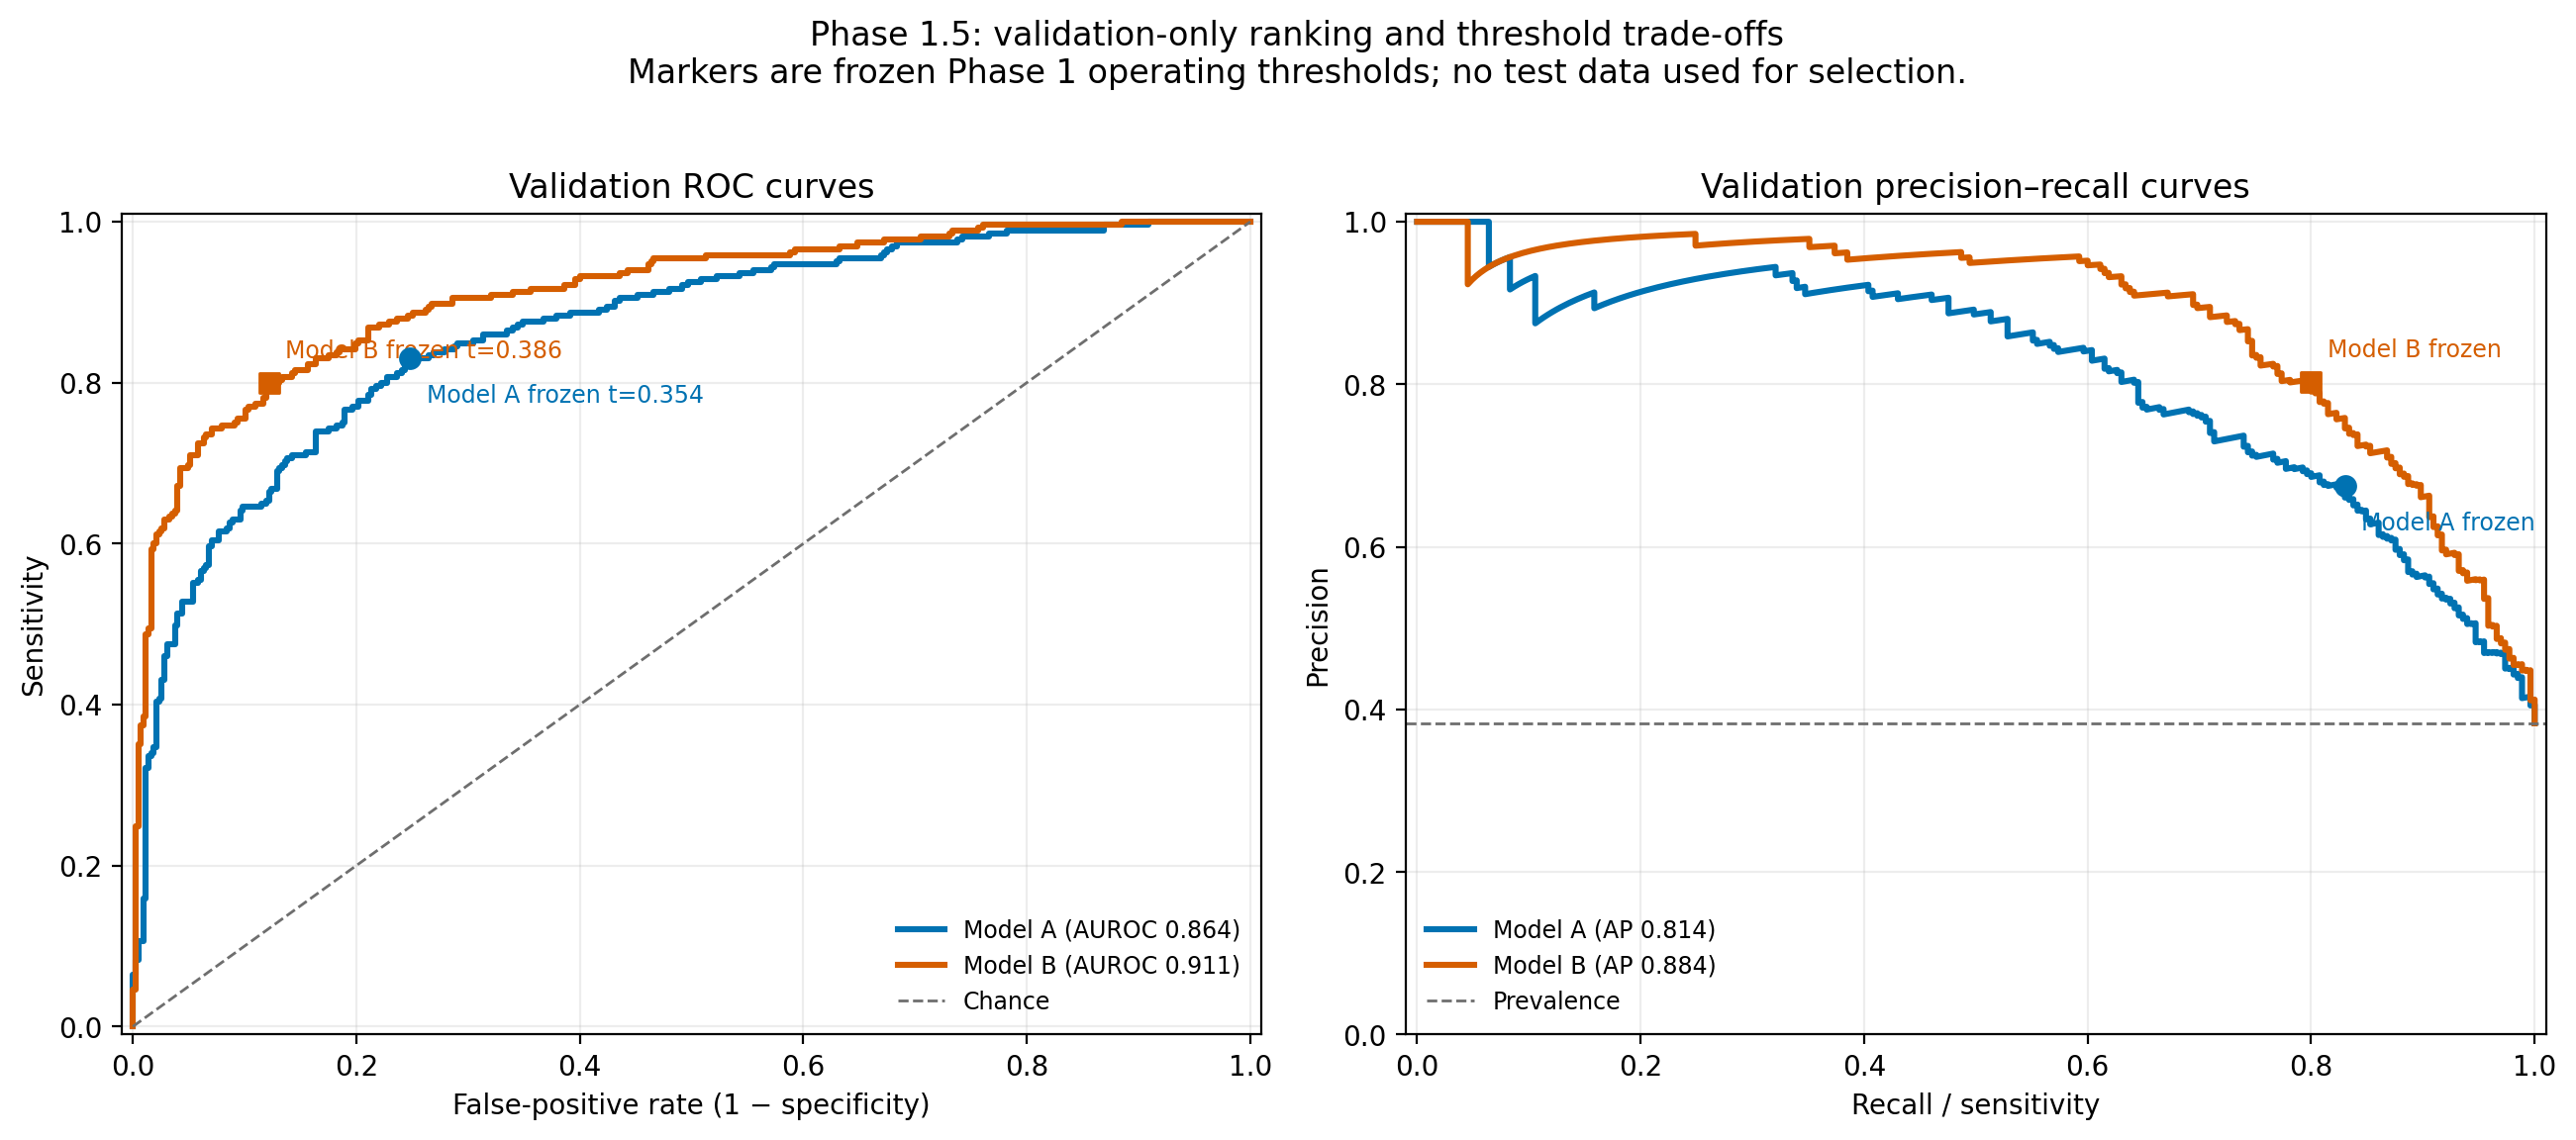

In [4]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports' / 'team_share' / 'PHASE1_5_KEY_FIGURE.png')))

## Development-only multi-view results

In [5]:
phase2b = pd.read_csv(ROOT / 'reports' / 'phase2b' / 'model_comparison.csv')
phase2b = phase2b.rename(columns={
    'auroc': 'AUROC', 'auprc': 'AUPRC',
    'specificity_at_0.85': 'Specificity @ >=85% sensitivity',
    'specificity_at_0.9': 'Specificity @ >=90% sensitivity',
})
phase2b[[
    'model', 'AUROC', 'AUPRC',
    'Specificity @ >=85% sensitivity',
    'Specificity @ >=90% sensitivity',
]]

,model,AUROC,AUPRC,Specificity @ >=85% sensitivity,Specificity @ >=90% sensitivity
0,mean,0.917061,0.897481,0.822014,0.714286
1,max,0.916689,0.899164,0.817330,0.707260
2,attention,0.916177,0.894082,0.812646,0.723653


## Controlled Phase 2C development experiment

**Scope.** This is one pre-registered development/validation experiment on the internal patient-safe split only. It does not use the historical official MURA valid/test split.

,model,auroc,auprc,at_sensitivity_85_threshold,at_sensitivity_85_sensitivity,at_sensitivity_85_specificity,at_sensitivity_85_precision,at_sensitivity_85_f1,at_sensitivity_85_false_positive,at_sensitivity_85_false_negative,...,at_sensitivity_90_false_negative,at_sensitivity_90_flagged_percent,at_sensitivity_95_threshold,at_sensitivity_95_sensitivity,at_sensitivity_95_specificity,at_sensitivity_95_precision,at_sensitivity_95_f1,at_sensitivity_95_false_positive,at_sensitivity_95_false_negative,at_sensitivity_95_flagged_percent
0,Frozen mean embedding,0.914983,0.878652,0.641280,0.851301,0.848341,0.781570,0.814947,64,40,...,26,52.821997,0.138672,0.951673,0.585308,0.593968,0.731429,175,13,62.373372
1,Partial fine-tuned mean embedding,0.913767,0.873423,0.530749,0.851301,0.831754,0.763333,0.804921,71,40,...,26,51.953690,0.172869,0.951673,0.571090,0.585812,0.725212,181,13,63.241679


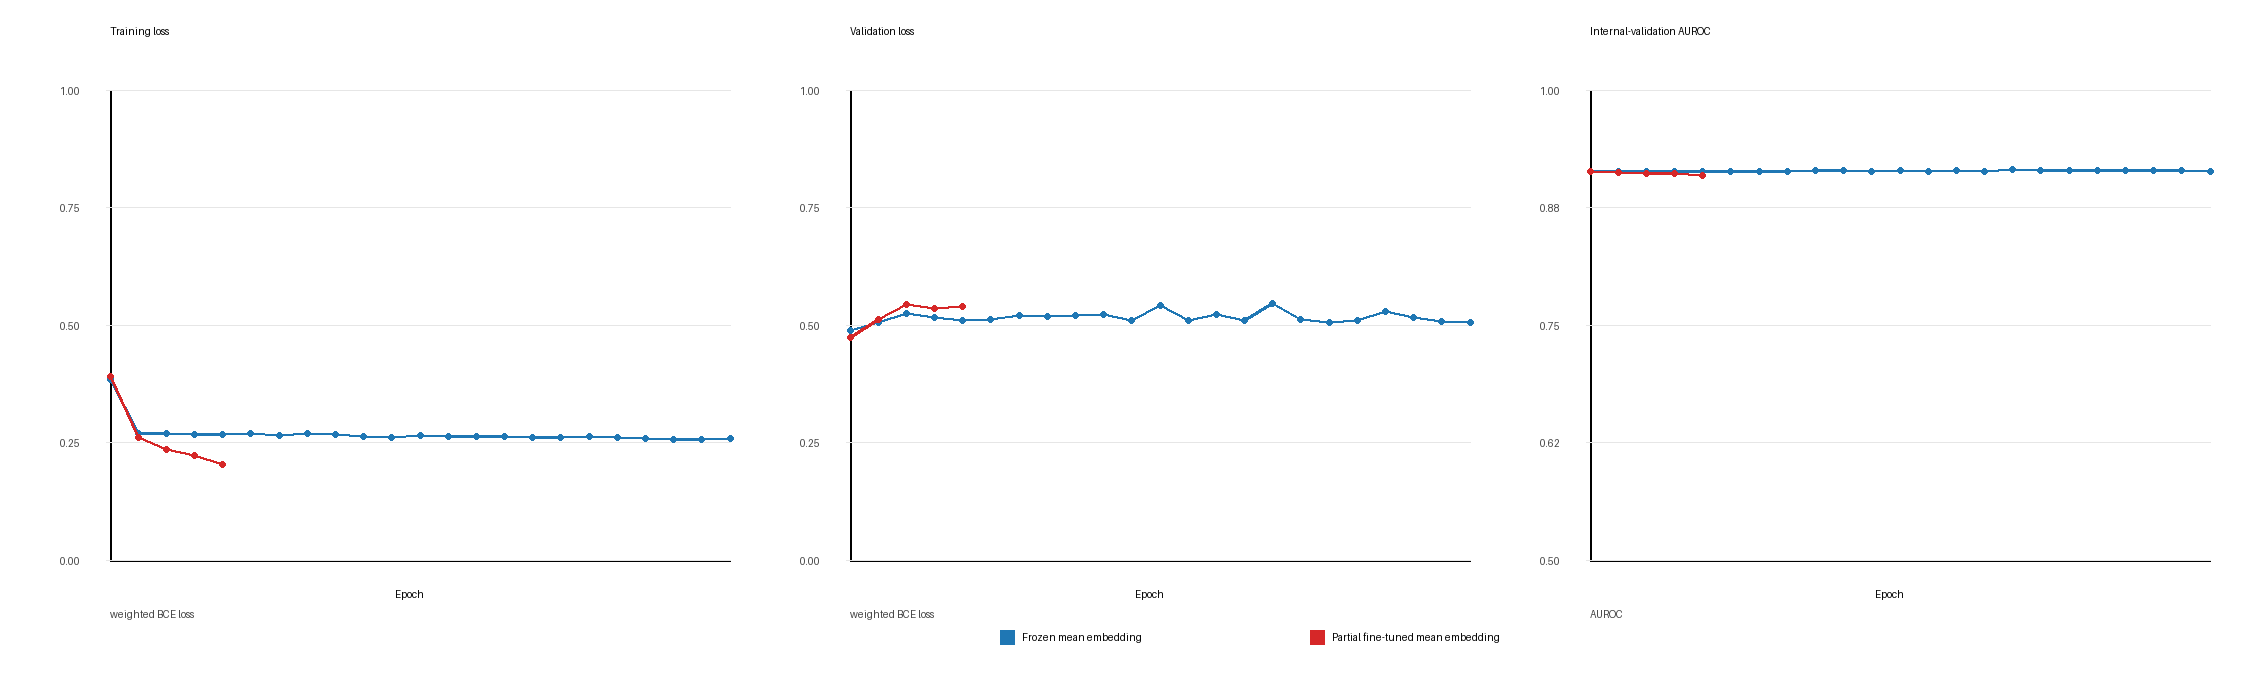

# Phase 2C summary — controlled study-level partial fine-tuning

## Scope and integrity

This is a DEVELOPMENT/INTERNAL-VALIDATION result only. The script accepted official MURA `train` rows only and used the existing patient-safe internal split. Official MURA `valid` was not loaded for training, model choice, threshold choice, calibration, or evaluation. Because official `valid` was observed historically in Phase 1, this report does not make an untouched-final-test claim.

Population checked: 9752 images, 3460 studies, 3267 patients; 2769 internal train and 691 internal validation studies.

## Models compared

- **Frozen mean embedding reference:** the existing fine-tuned Phase-1 ResNet-18 emits 512-D view embeddings; the encoder is frozen and a linear study head follows a masked mean over real views.
- **Partial fine-tuned mean embedding:** same study-level mean-embedding architecture, initialized from the same Phase-1 checkpoint; only ResNet `layer4` and the new study head are trainable.
- The positive-class weight was computed from internal-train studies only: 1.619678.

## Validation comparison

| model | auroc | auprc | at_sensitivity_85_threshold | at_sensitivity_85_sensitivity | at_sensitivity_85_specificity | at_sensitivity_85_precision | at_sensitivity_85_f1 | at_sensitivity_85_false_positive | at_sensitivity_85_false_negative | at_sensitivity_85_flagged_percent | at_sensitivity_90_threshold | at_sensitivity_90_sensitivity | at_sensitivity_90_specificity | at_sensitivity_90_precision | at_sensitivity_90_f1 | at_sensitivity_90_false_positive | at_sensitivity_90_false_negative | at_sensitivity_90_flagged_percent | at_sensitivity_95_threshold | at_sensitivity_95_sensitivity | at_sensitivity_95_specificity | at_sensitivity_95_precision | at_sensitivity_95_f1 | at_sensitivity_95_false_positive | at_sensitivity_95_false_negative | at_sensitivity_95_flagged_percent |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Frozen mean embedding | 0.914983 | 0.878652 | 0.641280 | 0.851301 | 0.848341 | 0.781570 | 0.814947 | 64 | 40 | 42.402315 | 0.334643 | 0.903346 | 0.710900 | 0.665753 | 0.766562 | 122 | 26 | 52.821997 | 0.138672 | 0.951673 | 0.585308 | 0.593968 | 0.731429 | 175 | 13 | 62.373372 |
| Partial fine-tuned mean embedding | 0.913767 | 0.873423 | 0.530749 | 0.851301 | 0.831754 | 0.763333 | 0.804921 | 71 | 40 | 43.415340 | 0.359029 | 0.903346 | 0.725118 | 0.676880 | 0.773885 | 116 | 26 | 51.953690 | 0.172869 | 0.951673 | 0.571090 | 0.585812 | 0.725212 | 181 | 13 | 63.241679 |

## Primary >=95% sensitivity policy

Each threshold below is the highest threshold that meets the pre-specified sensitivity floor on the same internal-validation split. Therefore these are development operating estimates, not independent performance evidence.

| model | at_sensitivity_95_threshold | at_sensitivity_95_sensitivity | at_sensitivity_95_specificity | at_sensitivity_95_precision | at_sensitivity_95_f1 | at_sensitivity_95_false_positive | at_sensitivity_95_false_negative | at_sensitivity_95_flagged_percent |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Frozen mean embedding | 0.138672 | 0.951673 | 0.585308 | 0.593968 | 0.731429 | 175 | 13 | 62.373372 |
| Partial fine-tuned mean embedding | 0.172869 | 0.951673 | 0.571090 | 0.585812 | 0.725212 | 181 | 13 | 63.241679 |

## Paired uncertainty

Candidate minus frozen reference, using 2,000 patient-cluster bootstrap replicates on the same validation studies:

| metric | difference_candidate_minus_baseline | ci_lower_95 | ci_upper_95 | n_bootstrap_requested | n_bootstrap_valid | seed | resampling_unit |
| --- | --- | --- | --- | --- | --- | --- | --- |
| AUROC | -0.001216 | -0.004395 | 0.002044 | 2000 | 2000 | 42 | patient cluster |
| AUPRC | -0.005229 | -0.019358 | 0.009981 | 2000 | 2000 | 42 | patient cluster |
| Specificity@95% | -0.014218 | -0.076402 | 0.092423 | 2000 | 2000 | 42 | patient cluster |

## Interpretation

The 95% CI for the specificity difference includes zero; a point estimate alone is not enough to claim that partial fine-tuning improved the 95% sensitivity policy.

The aggregate paired-error counts are in `error_summary.csv`; view-count and disagreement subgroups are descriptive in `subgroup_summary.csv`, including the internal-train tercile cutpoints used for disagreement. The non-selection padding/border/resize diagnostic is in `geometry_robustness_summary.csv`. Neither analysis establishes clinical causation. The historical Phase-2B attention result remains negative/inconclusive and was not retrained here.

## Error, subgroup, and robustness evidence

At their own >=95% sensitivity policies, partial fine-tuning fixed 8 validation errors but introduced 14; it fixed 2 false negatives and introduced 2. Both models therefore had 13 false negatives, while partial fine-tuning added 6 false positives.
The high-disagreement subgroup was essentially tied (0.732357 frozen vs 0.732750 partial AUROC); this exploratory subgroup does not justify further representation work. The 1-view, 2-view, and 3+-view rows are descriptive because the 1-view subgroup contains only 6 abnormal studies.
The geometry diagnostic found non-zero prediction/decision changes under display transformations for both models. This supports continued QC/shortcut investigation, but it does not demonstrate the clinical source of those changes or validate localization.

## Complexity and stopping rule

Frozen reference: 513 trainable / 11,177,025 total parameters; best epoch 16; runtime 9.6 seconds.
Partial model: 8,394,241 trainable / 11,177,025 total parameters; best epoch 1; runtime 2092.9 seconds.
Only the pre-registered reference and one partial fine-tuning run were performed. No hyperparameter sweep, new backbone, attention retraining, ensemble, Agentic AI, or test-set evaluation occurred.

## Decision gate

Partial fine-tuning did **not** provide a meaningful improvement: at >=95% sensitivity, specificity was 0.571090 versus 0.585308 for the frozen reference, and the paired confidence interval includes no improvement. Its ranking point estimates were also lower and the training curve showed an overfitting signal.
The ML core should therefore remain frozen at the simpler frozen mean-embedding reference. The single justified next project step is to advance the bounded deterministic safety policy and separately evaluated Agentic-AI layer, while treating input-QC/geometry sensitivity as a safety-evaluation requirement rather than as proof of a medical shortcut.

## Final status

- **PHASE 2C STATUS:** COMPLETE
- **MEANINGFUL IMPROVEMENT:** NO
- **ML CORE READY TO FREEZE:** YES
- **RECOMMENDED NEXT STEP:** Implement and evaluate the bounded deterministic safety policy and Agentic-AI design on a dedicated agent-evaluation set; do not continue architecture tuning on this already-used development split.


In [6]:
from IPython.display import Image, Markdown, display

phase2c = pd.read_csv(ROOT / 'reports' / 'phase2c' / 'model_comparison.csv')
display(Markdown(
    '**Scope.** This is one pre-registered development/validation experiment on the '
    'internal patient-safe split only. It does not use the historical official MURA valid/test split.'
))
display(phase2c)
display(Image(filename=str(ROOT / 'reports' / 'phase2c' / 'training_curves.png')))
display(Markdown((ROOT / 'reports' / 'phase2c' / 'PHASE2C_SUMMARY.md').read_text(encoding='utf-8')))

## Test-set governance

In [7]:
display(Markdown((ROOT / 'reports' / 'TEST_SET_GOVERNANCE.md').read_text(encoding='utf-8')))

# Test-set governance

## Historical Phase-1 use of official MURA `valid`

Official MURA `valid` was used **once** as the frozen Phase-1 reference evaluation. Before it was opened, the project used official MURA `train` to create patient-level internal training and validation populations, and selected the historical operating thresholds from internal validation study predictions. The historical baseline regularization procedure is preserved as historical evidence; the current Checkpoint 1 baseline corrects this by selecting Logistic Regression `C` with patient-grouped CV inside internal train only. Model B development choices were made without opening official MURA `valid`.

After official-valid was opened, the project observed the Phase-1 study-level predictions, metrics/bootstraps, model comparison, and descriptive error analyses. Those results are preserved as historical evidence in the repository.

## Rule for all later work

Because the official-valid result has now been observed, it is not an untouched evaluation population for later model, threshold, calibration, architecture, aggregation, or agent selection. Phase 2 and future development may cite it only as a historical frozen reference; they must not inspect its labels to choose anything. This applies even when a new candidate is compared with an old Phase-1 result.

Legacy Phase-1 utilities retain an explicit opt-in sealed-test prediction
export for reproducibility of the historical reference. They are not part of
the corrected Checkpoint 1 development flow. The current result builder
(`scripts/build_checkpoint1_results.py`) refuses inputs named as official-valid
or test predictions, and this branch's current reports were built from internal
validation inputs only.

## Open methodological decision for advanced claims

If a genuinely untouched advanced-model evaluation population is required, the team and lecturer must choose and pre-register one of these scientifically defensible options:

1. patient-grouped development cross-validation with an explicit transparent reuse limitation;
2. compatible external validation data after confirming task/anatomy/label compatibility; or
3. a lecturer-approved final evaluation protocol.

Do not silently create a “new test” from data already used for development and call it untouched.
